<a href="https://colab.research.google.com/github/prajjwal-5519/Room-Occupancy-Detection/blob/main/Occupancy_Detection_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Room Occupancy Detection from Environmental Sensors using Naïve Bayes

**Domain:** Embedded Sensing / IoT (ECE with AIML)
**Task:** Binary classification (Supervised Learning)
**Classifiers:** Gaussian Naïve Bayes and Kernel Naïve Bayes (kernel trick via Kernel Density Estimation)
**Dataset:** UCI *Occupancy Detection* (Candanedo & Feldheim, 2016), CC BY 4.0

---

## 1. Problem Statement
Smart buildings save energy when lighting, HVAC and ventilation are switched according to whether a room is
actually occupied. Camera-based occupancy detection is costly and raises privacy concerns. A low-cost sensor node
(DHT-type temperature/humidity sensor, LDR/lux sensor and an NDIR CO2 sensor on a microcontroller such as ESP32)
can sense the room instead.

**Goal:** Given readings from the sensor node (Temperature, Relative Humidity, Light, CO2, Humidity Ratio), build a
machine-learning pipeline that classifies whether an office room is **Occupied (1)** or **Not Occupied (0)**.

## 2. Hardware (Sensor) Setup Mapped to Features
| Feature | Sensor | Unit |
|---|---|---|
| Temperature | Digital temperature sensor (e.g. DHT22 / SHT31) | °C |
| Humidity | Digital humidity sensor (same package) | % RH |
| Light | LDR / BH1750 lux sensor | Lux |
| CO2 | NDIR CO2 sensor (e.g. MH-Z19 / SCD30) | ppm |
| HumidityRatio | Derived from Temperature and Humidity | kg water-vapour / kg air |

**Label:** `Occupancy` (0 = not occupied, 1 = occupied), obtained from time-stamped photos taken every minute.

## 3. Pipeline
Load data → Save as CSV → EDA → 80/20 stratified split → Train Gaussian NB and Kernel NB → Evaluate
(Accuracy, Confusion Matrix, Type I/II error, Precision, Recall, F1, Heat map) → Compare and conclude.

## 4. Import Libraries

In [ ]:
import os, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KernelDensity
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 5. Load the Dataset and Save it as a `.csv` File
The UCI repository supplies three files (`datatraining.txt`, `datatest.txt`, `datatest2.txt`). They are merged into a
single table (20,560 readings) and saved as **`occupancy_dataset.csv`**. We then do our own 80/20 split.

In [ ]:
CSV_PATH = "occupancy_dataset.csv"
URL = "https://archive.ics.uci.edu/static/public/357/occupancy+detection.zip"

if not os.path.exists(CSV_PATH):
    try:
        raw = urllib.request.urlopen(URL, timeout=60).read()
        frames = []
        with zipfile.ZipFile(io.BytesIO(raw)) as z:
            for name in z.namelist():
                if name.endswith(".txt"):
                    df_part = pd.read_csv(z.open(name))
                    df_part = df_part.loc[:, ~df_part.columns.str.contains("^Unnamed")]
                    frames.append(df_part)
        df = pd.concat(frames, ignore_index=True)
        df.to_csv(CSV_PATH, index=False)
        print("Downloaded and saved:", CSV_PATH)
    except Exception as e:
        print("Automatic download failed:", e)
        print("Download the zip from https://archive.ics.uci.edu/dataset/357/occupancy+detection,")
        print("merge the three .txt files into occupancy_dataset.csv and upload it using the Files panel on the left.")

df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
df.head()

Downloaded and saved: occupancy_dataset.csv
Shape: (20560, 7)


,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
0,2015-02-02 14:19:00,23.7000,26.272,585.200000,749.200000,0.004764,1
1,2015-02-02 14:19:59,23.7180,26.290,578.400000,760.400000,0.004773,1
2,2015-02-02 14:21:00,23.7300,26.230,572.666667,769.666667,0.004765,1
3,2015-02-02 14:22:00,23.7225,26.125,493.750000,774.750000,0.004744,1
4,2015-02-02 14:23:00,23.7540,26.200,488.600000,779.000000,0.004767,1


## 6. Exploratory Data Analysis

In [ ]:
print(df.info())
print("\nMissing values per column:\n", df.isnull().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20560 entries, 0 to 20559
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           20560 non-null  object 
 1   Temperature    20560 non-null  float64
 2   Humidity       20560 non-null  float64
 3   Light          20560 non-null  float64
 4   CO2            20560 non-null  float64
 5   HumidityRatio  20560 non-null  float64
 6   Occupancy      20560 non-null  int64  
dtypes: float64(5), int64(1), object(1)
memory usage: 1.1+ MB
None

Missing values per column:
 date             0
Temperature      0
Humidity         0
Light            0
CO2              0
HumidityRatio    0
Occupancy        0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Temperature,20560.0,20.906212,1.055315,19.000000,20.200000,20.700000,21.525000,24.408333
Humidity,20560.0,27.655925,4.982154,16.745000,24.500000,27.290000,31.290000,39.500000
Light,20560.0,130.756622,210.430875,0.000000,0.000000,0.000000,301.000000,1697.250000
CO2,20560.0,690.553276,311.201281,412.750000,460.000000,565.416667,804.666667,2076.500000
HumidityRatio,20560.0,0.004228,0.000768,0.002674,0.003719,0.004292,0.004832,0.006476
Occupancy,20560.0,0.231031,0.421503,0.000000,0.000000,0.000000,0.000000,1.000000


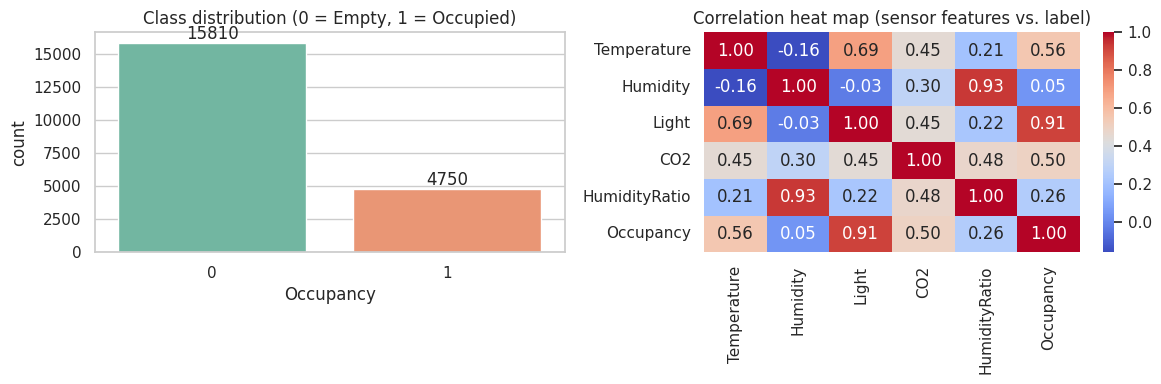

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x="Occupancy", hue="Occupancy", data=df, ax=ax[0], palette="Set2", legend=False)
ax[0].set_title("Class distribution (0 = Empty, 1 = Occupied)")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                   ha="center", va="bottom")

features_only = df.drop(columns=["date", "Occupancy"], errors="ignore")
sns.heatmap(features_only.assign(Occupancy=df["Occupancy"]).corr(),
            annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation heat map (sensor features vs. label)")
plt.tight_layout()
plt.show()

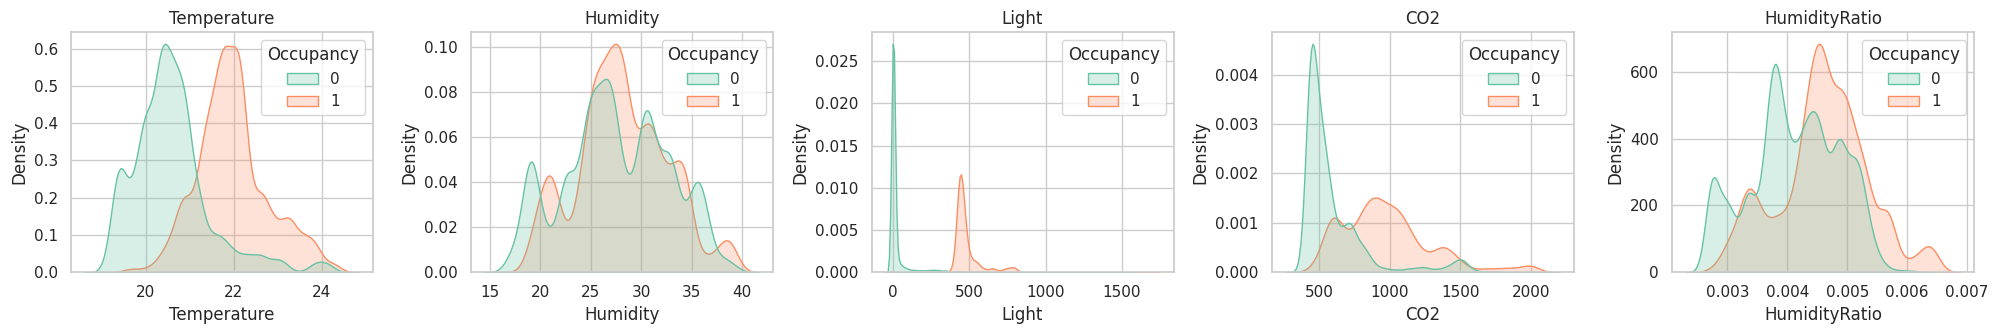

In [ ]:
sensor_cols = ["Temperature", "Humidity", "Light", "CO2", "HumidityRatio"]
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5))
for col, a in zip(sensor_cols, axes):
    sns.kdeplot(data=df, x=col, hue="Occupancy", fill=True, common_norm=False, ax=a, palette="Set2", warn_singular=False)
    a.set_title(col)
plt.tight_layout()
plt.show()

## 7. Features, Label and 80 % / 20 % Train-Test Split
`date` is dropped so that the model uses **only sensor readings**. The split is stratified so both sets keep the
same class ratio.

In [ ]:
X = df[sensor_cols]
y = df["Occupancy"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set : {X_train.shape[0]} samples (80%)")
print(f"Testing set  : {X_test.shape[0]} samples (20%)")
print("\nClass ratio  train:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Class ratio  test :", y_test.value_counts(normalize=True).round(3).to_dict())

Training set : 16448 samples (80%)
Testing set  : 4112 samples (20%)

Class ratio  train: {0: 0.769, 1: 0.231}
Class ratio  test : {0: 0.769, 1: 0.231}


## 8. Models

### 8.1 Gaussian Naïve Bayes
Assumes each sensor reading, given the class, follows a Gaussian (normal) distribution and that features are
conditionally independent:

$$P(C_k \mid x) \propto P(C_k)\prod_{i} P(x_i \mid C_k), \qquad P(x_i \mid C_k)=\mathcal{N}(x_i;\mu_{ik},\sigma_{ik}^2)$$

### 8.2 Kernel Naïve Bayes (kernel trick)
Sensor data such as Light and CO2 is skewed and not truly Gaussian. Instead of forcing a normal shape, we estimate
each class-conditional density $P(x_i \mid C_k)$ with a **Gaussian kernel (Kernel Density Estimation)**:

$$\hat{p}(x_i \mid C_k)=\frac{1}{n_k h}\sum_{j=1}^{n_k} K\!\left(\frac{x_i-x_{ij}}{h}\right)$$

The kernel $K$ and bandwidth $h$ replace the fixed Gaussian assumption, which is how the kernel idea is applied to
Naïve Bayes. The bandwidth is chosen by cross-validation on the **training set only**.

In [ ]:
class KernelNaiveBayes(BaseEstimator, ClassifierMixin):
    """Naive Bayes whose per-feature class-conditional densities are estimated with KDE."""

    def __init__(self, bandwidth=0.3, kernel="gaussian"):
        self.bandwidth = bandwidth
        self.kernel = kernel

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.log_priors_ = np.log(np.array([(y == c).mean() for c in self.classes_]))
        self.kdes_ = []
        for c in self.classes_:
            Xc = X[y == c]
            self.kdes_.append([
                KernelDensity(kernel=self.kernel, bandwidth=self.bandwidth, rtol=1e-3).fit(Xc[:, [j]])
                for j in range(X.shape[1])
            ])
        return self

    def _joint_log_likelihood(self, X):
        X = np.asarray(X, dtype=float)
        jll = np.zeros((X.shape[0], len(self.classes_)))
        for k, kde_list in enumerate(self.kdes_):
            log_lik = sum(kde.score_samples(X[:, [j]]) for j, kde in enumerate(kde_list))
            jll[:, k] = self.log_priors_[k] + log_lik
        return jll

    def predict(self, X):
        return self.classes_[np.argmax(self._joint_log_likelihood(X), axis=1)]

    def predict_proba(self, X):
        jll = self._joint_log_likelihood(X)
        jll -= jll.max(axis=1, keepdims=True)
        p = np.exp(jll)
        return p / p.sum(axis=1, keepdims=True)

### 8.3 Choose the KDE bandwidth (3-fold cross-validation on the training set only)

In [ ]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
bandwidths = [0.05, 0.1, 0.2, 0.5]
cv_scores = []

for h in bandwidths:
    pipe = make_pipeline(StandardScaler(), KernelNaiveBayes(bandwidth=h))
    score = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy").mean()
    cv_scores.append(score)
    print(f"bandwidth = {h:<5} -> CV accuracy = {score:.4f}")

best_h = bandwidths[int(np.argmax(cv_scores))]
print("\nBest bandwidth:", best_h)

bandwidth = 0.05  -> CV accuracy = 0.9795
bandwidth = 0.1   -> CV accuracy = 0.9805
bandwidth = 0.2   -> CV accuracy = 0.9807
bandwidth = 0.5   -> CV accuracy = 0.9677

Best bandwidth: 0.2


### 8.4 Train both models

In [ ]:
gnb = make_pipeline(StandardScaler(), GaussianNB())
knb = make_pipeline(StandardScaler(), KernelNaiveBayes(bandwidth=best_h))

gnb.fit(X_train, y_train)
knb.fit(X_train, y_train)

y_pred_gnb = gnb.predict(X_test)
y_pred_knb = knb.predict(X_test)
print("Both models trained and predictions made on the 20% test set.")

Both models trained and predictions made on the 20% test set.


## 9. Evaluation Metrics
Positive class = **Occupied (1)**. From the confusion matrix (TN, FP, FN, TP):

| Metric | Formula | Meaning here |
|---|---|---|
| Accuracy | (TP+TN) / total | Overall correct predictions |
| **Type I error** (False Positive Rate, α) | FP / (FP+TN) | Room is empty but model says occupied (energy wasted) |
| **Type II error** (False Negative Rate, β) | FN / (FN+TP) | Room is occupied but model says empty (comfort/safety issue) |
| Precision | TP / (TP+FP) | Of all "occupied" predictions, how many were right |
| Recall (Sensitivity) | TP / (TP+FN) | Of all truly occupied cases, how many were found |
| F1 score | 2·P·R / (P+R) | Harmonic mean of precision and recall |

In [ ]:
def evaluate(model_name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    metrics = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Type I Error (FPR)": fp / (fp + tn),
        "Type II Error (FNR)": fn / (fn + tp),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
    }

    print("=" * 62)
    print(f"  {model_name}")
    print("=" * 62)
    print(f"Confusion Matrix  [TN={tn}  FP={fp}  FN={fn}  TP={tp}]")
    print(cm, "\n")
    for k, v in metrics.items():
        print(f"{k:<22}: {v:.4f}   ({v*100:.2f} %)")
    print("\nClassification Report:\n",
          classification_report(y_true, y_pred, target_names=["Not Occupied (0)", "Occupied (1)"]))

    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=True, ax=ax[0],
                xticklabels=["Pred: Empty", "Pred: Occupied"],
                yticklabels=["Actual: Empty", "Actual: Occupied"])
    ax[0].set_title(f"{model_name}\nConfusion Matrix Heat Map (counts)")

    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=True, fmt=".3f", cmap="YlGnBu", cbar=True, ax=ax[1],
                xticklabels=["Pred: Empty", "Pred: Occupied"],
                yticklabels=["Actual: Empty", "Actual: Occupied"])
    ax[1].set_title(f"{model_name}\nNormalised Heat Map (row-wise rates)")
    plt.tight_layout()
    plt.show()
    return metrics

### 9.1 Gaussian Naïve Bayes

  Gaussian Naive Bayes
Confusion Matrix  [TN=3017  FP=145  FN=1  TP=949]
[[3017  145]
 [   1  949]] 

Accuracy              : 0.9645   (96.45 %)
Type I Error (FPR)    : 0.0459   (4.59 %)
Type II Error (FNR)   : 0.0011   (0.11 %)
Precision             : 0.8675   (86.75 %)
Recall                : 0.9989   (99.89 %)
F1 Score              : 0.9286   (92.86 %)

Classification Report:
                   precision    recall  f1-score   support

Not Occupied (0)       1.00      0.95      0.98      3162
    Occupied (1)       0.87      1.00      0.93       950

        accuracy                           0.96      4112
       macro avg       0.93      0.98      0.95      4112
    weighted avg       0.97      0.96      0.97      4112



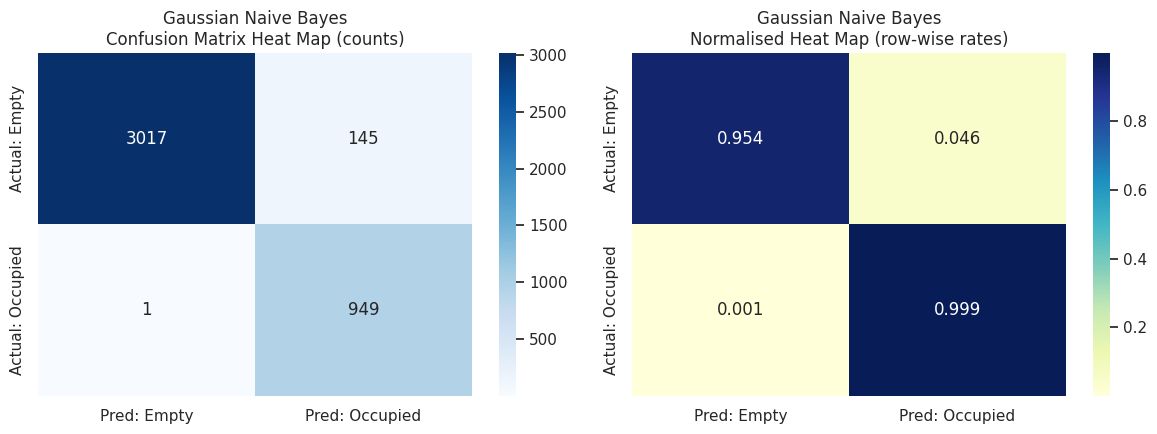

In [ ]:
m_gnb = evaluate("Gaussian Naive Bayes", y_test, y_pred_gnb)

### 9.2 Kernel Naïve Bayes (KDE)

  Kernel Naive Bayes (bandwidth=0.2)
Confusion Matrix  [TN=3100  FP=62  FN=30  TP=920]
[[3100   62]
 [  30  920]] 

Accuracy              : 0.9776   (97.76 %)
Type I Error (FPR)    : 0.0196   (1.96 %)
Type II Error (FNR)   : 0.0316   (3.16 %)
Precision             : 0.9369   (93.69 %)
Recall                : 0.9684   (96.84 %)
F1 Score              : 0.9524   (95.24 %)

Classification Report:
                   precision    recall  f1-score   support

Not Occupied (0)       0.99      0.98      0.99      3162
    Occupied (1)       0.94      0.97      0.95       950

        accuracy                           0.98      4112
       macro avg       0.96      0.97      0.97      4112
    weighted avg       0.98      0.98      0.98      4112



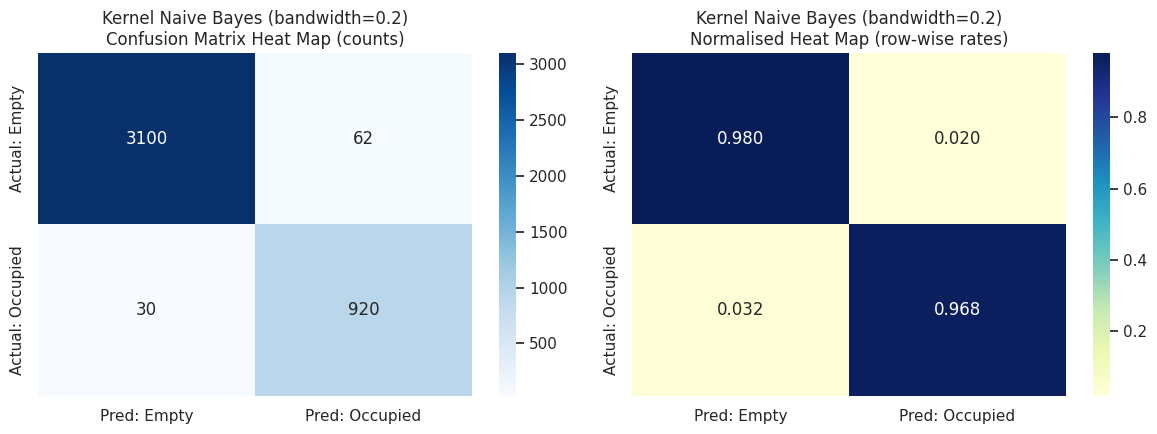

In [ ]:
m_knb = evaluate(f"Kernel Naive Bayes (bandwidth={best_h})", y_test, y_pred_knb)

## 10. Model Comparison

,Accuracy,Type I Error (FPR),Type II Error (FNR),Precision,Recall,F1 Score
Gaussian NB,0.9645,0.0459,0.0011,0.8675,0.9989,0.9286
Kernel NB (KDE),0.9776,0.0196,0.0316,0.9369,0.9684,0.9524


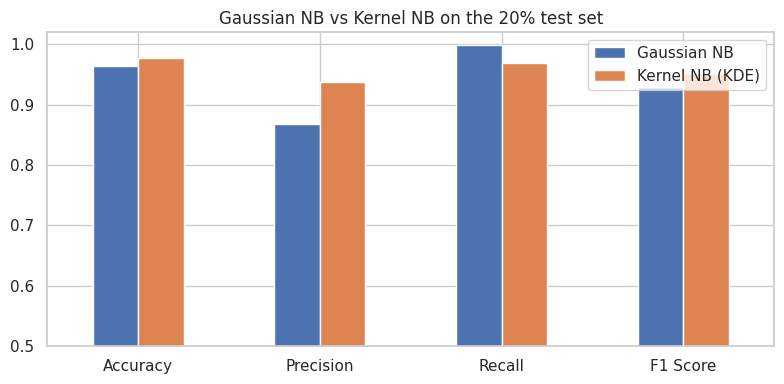

In [ ]:
results = pd.DataFrame({"Gaussian NB": m_gnb, "Kernel NB (KDE)": m_knb}).T
display(results.style.format("{:.4f}").highlight_max(axis=0, color="#c6efce"))

ax = results[["Accuracy", "Precision", "Recall", "F1 Score"]].T.plot(kind="bar", figsize=(8, 4), rot=0)
ax.set_ylim(0.5, 1.02)
ax.set_title("Gaussian NB vs Kernel NB on the 20% test set")
plt.tight_layout()
plt.show()

## 11. Observations and Conclusion (edit with your own numbers)
- The dataset has 5 sensor features and a binary label; ~77 % of readings are "Not Occupied", so **accuracy alone can
  be misleading**. Precision, recall, F1 and the Type I/II errors give the complete picture.
- **Light** and **CO2** are the strongest indicators of occupancy (see correlation heat map). Humidity and Humidity
  Ratio are strongly correlated with each other (the ratio is derived from them), which violates Naïve Bayes' independence assumption, yet the classifier
  can still perform well.
- Gaussian NB assumes normally distributed sensors. Kernel NB relaxes this with KDE, so it can model the skewed Light
  and CO2 distributions better.
- **Type I error** (false alarm) wastes energy by switching on equipment for an empty room; **Type II error** (missed
  detection) leaves an occupied room without lighting/ventilation. Choose the model by which error matters more for
  the application.

**Limitations / future work:** the data is a time series from one office room, so a random split can be optimistic;
a chronological split or testing on a different room would be a stricter check. Other ideas: add time-of-day
features, try SVM with RBF kernel for comparison, and deploy the trained model on an ESP32 or Raspberry Pi.

**Reference:** L. M. Candanedo and V. Feldheim, "Accurate occupancy detection of an office room from light,
temperature, humidity and CO2 measurements using statistical learning models," *Energy and Buildings*, vol. 112, 2016.
Dataset: UCI Machine Learning Repository, https://doi.org/10.24432/C5X01N (CC BY 4.0).